# UTS Graf Sains Data 
**Nama:** Yulia Eka Restania  
**NIM:** 23031554199  
**Matakuliah:** Graf Sains Data - 2023E  

**Dataset:** RetailRocket (`events.csv`, Kaggle - Roman Zykov)  
**Fold training (P1):** 27/05/2015 - 15/08/2015  
**Fold testing (P2):** 16/08/2015 - 05/09/2015  

> Asumsi: kolom `timestamp` berupa *unix epoch milidetik* (UTC). Batas tanggal inklusif.  
> Graf Neo4j dibangun **hanya dari fold training**; fold testing dipakai sebagai *ground truth* evaluasi (Hit@5, NDCG@5).  
> Screenshot disimpan di folder `docs/` pada repo ini.

**Daftar isi:** 1.1 Persiapan lingkungan → 1.2 Tutorial driver Neo4j → 1.3 Impor data → 2.1 Wrangling & EDA → 2.2 Analytics

## 0. Setup
```bash
uv venv myvenv --python 3.10 && source myvenv/bin/activate
uv pip install "neo4j>=5.20" pandas numpy scipy networkx matplotlib tqdm
```
**Catatan penting:** `requirements.txt` pada soal memuat `neo4j==4.2.1`, padahal `driver.execute_query(...)` (tutorial 1.2) baru ada di driver **>= 5.5**. Maka digunakan driver 5.x agar tutorial berjalan.

In [1]:
import os, sys, math
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import sparse
from tqdm import tqdm
from neo4j import GraphDatabase, RoutingControl

URI  = os.getenv("NEO4J_URI", "neo4j://127.0.0.1:7687")
AUTH = (os.getenv("NEO4J_USER", "neo4j"), os.getenv("NEO4J_PASSWORD", "lemontea"))
DB   = os.getenv("NEO4J_DB", "neo4j")

SRC_CSV   = "data/events.csv"
TRAIN_CSV = "data/events_train.csv"
TEST_CSV  = "data/events_test.csv"

P1 = ("2015-05-27", "2015-08-15")   # fold training
P2 = ("2015-08-16", "2015-09-05")   # fold testing
SEED = 42                           # seed untuk proses acak (reproducible)
BATCH_SIZE = 10_000

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke Neo4j")

Terhubung ke Neo4j


## 1. Tugas Pendahuluan
### 1.1 Persiapan dan Perkenalan Lingkungan
Langkah yang dijalankan (Windows, CMD):
```cmd
cd /d D:\uts-gsd
python -m venv myenv
myenv\Scripts\activate.bat
pip install "neo4j>=5.20" pandas numpy scipy networkx matplotlib tqdm jupyter ipykernel
```
- `conda deactivate` tidak diperlukan (conda tidak terpasang / tidak ada environment conda aktif).
- Paket dipasang manual, bukan dari `requirements.txt` soal, karena `neo4j==4.2.1` tidak memiliki `driver.execute_query()` (baru ada di driver >= 5.5).
- Virtual environment dipakai untuk mengisolasi dependensi proyek dari paket lain di laptop.

In [2]:
import sys, neo4j
print("Python :", sys.version.split()[0])
print("Driver :", neo4j.__version__)
print("Venv   :", sys.executable)

Python : 3.11.0
Driver : 6.4.1
Venv   : d:\uts-gsd\myenv\Scripts\python.exe


### 1.2 Mempelajari Penggunaan Driver Neo4j
Tutorial: membuat simpul `Person` dan relasi `KNOWS` memakai `driver.execute_query()`.

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DB,
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DB, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")
print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


Query di Neo4j Browser untuk melihat grafnya:
```cypher
MATCH p = (a:Person)-[:KNOWS]->(f) RETURN p
```
![Graf pertemanan](docs/graf_tutorial.png)

**Pertanyaan Pendahuluan (Checkpoint)**

1. **Nama database yang digunakan:** `neo4j`, terlihat dari parameter `database_="neo4j"` pada `execute_query`.
2. **Akses lain untuk database lain dalam 1 instance:**
   - Python: parameter `database_="namadb"` pada `execute_query` / `driver.session(database=...)`.
   - Cypher: `USE namadb` (di Neo4j Browser: `:use namadb`).
   - Melihat daftar database: `SHOW DATABASES`; membuat database baru: `CREATE DATABASE namadb` (memerlukan edisi yang mendukung multi-database).
3. **Jenis graf pertemanan:** graf **berarah** (*directed*) dengan simpul berlabel `Person` dan relasi `KNOWS`, tanpa bobot. Arthur menunjuk ke Guinevere, Lancelot, dan Merlin (bentuk bintang / *star*). `MERGE` membuat simpul dan relasi hanya jika belum ada (idempoten).

**CYPHER Total Reset** - membersihkan data tutorial sebelum lanjut (hati-hati pada *shared database*):

In [4]:
driver.execute_query("MATCH (n) DETACH DELETE n", database_=DB)
print("Database dikosongkan.")

Database dikosongkan.


### 1.3 Persiapan Impor Data dari RetailRocket
Unduh dataset (CMD, satu baris), lalu ekstrak ke folder `data`:
```cmd
curl.exe -L -o ecommerce-dataset.zip https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset
mkdir data
tar -xf ecommerce-dataset.zip -C data
```
Fitur pada `events.csv`:
- `timestamp`: waktu dalam format unix epoch (milidetik)
- `visitorid`: ID unik pengunjung
- `event`: jenis interaksi (`view`, `addtocart`, `transaction`)
- `itemid`: ID unik produk
- `transactionid`: ID transaksi (hanya terisi saat event `transaction`)

Proses impor ke Neo4j (koneksi, constraint, batch, Cypher) dilakukan pada bagian 2.1 di bawah, setelah fold training difilter.

In [5]:
assert os.path.exists(SRC_CSV), f"{SRC_CSV} belum ada - unduh & ekstrak dataset dulu"
print(pd.read_csv(SRC_CSV, nrows=5))

       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN


## 2. Soal UTS

## 2.1 Wrangling dan EDA
### (Soal 1-2) Filter periode berdasarkan timestamp dan simpan ke `.csv`
Timestamp (ms) dikonversi ke tanggal UTC, lalu difilter sesuai P1 dan P2. Pemrosesan per-*chunk* agar hemat memori.

In [6]:
def in_range(dates, rng):
    return (dates >= pd.Timestamp(rng[0])) & (dates <= pd.Timestamp(rng[1]))

if not os.path.exists(SRC_CSV):
    sys.exit(f"File {SRC_CSV} tidak ditemukan. Unduh & ekstrak dataset Kaggle dulu.")

first_tr = first_te = True
n_all = 0
tmin, tmax = None, None
for chunk in tqdm(pd.read_csv(SRC_CSV, chunksize=500_000), desc="Filter"):
    n_all += len(chunk)
    d = pd.to_datetime(chunk["timestamp"], unit="ms", utc=True).dt.tz_localize(None)
    tmin = d.min() if tmin is None else min(tmin, d.min())
    tmax = d.max() if tmax is None else max(tmax, d.max())
    day = d.dt.normalize()

    tr = chunk[in_range(day, P1)]
    te = chunk[in_range(day, P2)]
    tr.to_csv(TRAIN_CSV, mode="w" if first_tr else "a", header=first_tr, index=False)
    te.to_csv(TEST_CSV,  mode="w" if first_te else "a", header=first_te, index=False)
    first_tr = first_te = False

print(f"Total baris sumber : {n_all:,}  (rentang {tmin} s.d. {tmax} UTC)")
train = pd.read_csv(TRAIN_CSV); test = pd.read_csv(TEST_CSV)
print(f"Train: {len(train):,} baris | Test: {len(test):,} baris")
print(train["event"].value_counts(), "\n", test["event"].value_counts())

Filter: 6it [00:03,  1.51it/s]


Total baris sumber : 2,756,101  (rentang 2015-05-03 03:00:04.384000 s.d. 2015-09-18 02:59:47.788000 UTC)
Train: 1,669,845 baris | Test: 373,709 baris
event
view           1614271
addtocart        41864
transaction      13710
Name: count, dtype: int64 
 event
view           360639
addtocart        9859
transaction      3211
Name: count, dtype: int64


### Impor fold training ke Neo4j
Memakai mekanisme *batch* (`chunksize`) seperti pada soal 1.3. `CREATE CONSTRAINT` memakai sintaks Neo4j 5. Query relasi dipisah per jenis `event` (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`) agar kompatibel dan mudah dibaca.

In [7]:
RESET = True   # True = kosongkan database sebelum impor (hati-hati pada shared database!)

EVENT_REL = {
    "view":        ("VIEWED", ""),
    "addtocart":   ("ADDED_TO_CART", ""),
    "transaction": ("BOUGHT", ", transactionId: row.transactionid"),
}

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    for event, (rel, extra) in EVENT_REL.items():
        rows = [r for r in batch if r["event"] == event]
        if not rows:
            continue
        tx.run(f"""
            UNWIND $rows AS row
            MERGE (v:Visitor {{visitorId: row.visitorid}})
            MERGE (i:Item {{itemId: row.itemid}})
            CREATE (v)-[:{rel} {{timestamp: row.timestamp{extra}}}]->(i)
        """, rows=rows)

with driver.session(database=DB) as session:
    if RESET:
        session.run("MATCH (n) DETACH DELETE n")
    create_constraints(session)

    total_rows = sum(1 for _ in open(TRAIN_CSV)) - 1
    total_chunks = (total_rows // BATCH_SIZE) + 1
    for chunk in tqdm(pd.read_csv(TRAIN_CSV, chunksize=BATCH_SIZE),
                      total=total_chunks, desc="Mengimpor Batch Data"):
        # transactionid kosong -> "" ; hindari format float ("123.0")
        chunk["transactionid"] = (chunk["transactionid"].astype("Int64").astype(str)
                                  .replace("<NA>", ""))
        session.execute_write(import_batch, chunk.to_dict(orient="records"))
print("Proses impor berhasil.")

Mengimpor Batch Data: 100%|██████████| 167/167 [01:29<00:00,  1.86it/s]

Proses impor berhasil.


### (Soal 3) Komposisi subgraph (jenis simpul & jumlahnya) dengan Python API
**Penjelasan Cypher**
- `MATCH (n)` mengambil seluruh simpul; `labels(n)[0]` mengambil label utama (`Visitor` / `Item`); `count(*)` menghitung jumlah simpul per label (agregasi dikelompokkan otomatis oleh `AS label`).
- `MATCH ()-[r]->()` mengambil seluruh relasi; `type(r)` memberi jenis relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).

In [8]:
Q_NODES = """
MATCH (n)
RETURN labels(n)[0] AS label, count(*) AS jumlah
ORDER BY jumlah DESC
"""
Q_RELS = """
MATCH ()-[r]->()
RETURN type(r) AS relasi, count(*) AS jumlah
ORDER BY jumlah DESC
"""
def run_df(q, **params):
    records, _, _ = driver.execute_query(q, database_=DB, routing_=RoutingControl.READ, **params)
    return pd.DataFrame([r.data() for r in records])

df_nodes = run_df(Q_NODES); df_rels = run_df(Q_RELS)
print("Komposisi simpul:"); display(df_nodes)
print("Komposisi relasi:"); display(df_rels)

Komposisi simpul:


,label,jumlah
0,Visitor,865515
1,Item,189762


Komposisi relasi:


,relasi,jumlah
0,VIEWED,1614271
1,ADDED_TO_CART,41864
2,BOUGHT,13710


### (Soal 4) VSM terhadap simpul User (Visitor)
Graf bersifat *bipartit* (Visitor - Item). Setiap Visitor direpresentasikan sebagai vektor pada ruang Item (dimensi = jumlah Item unik). Nilai sel = keberadaan interaksi (biner). Bobot `view=1, addtocart=3, transaction=5` dapat dipakai sebagai alternatif.

In [9]:
Q_PAIRS = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i, count(r) AS n,
       sum(CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END) AS w
"""
pairs = run_df(Q_PAIRS)

users = np.sort(pairs["u"].unique()); items = np.sort(pairs["i"].unique())
uidx = {u: k for k, u in enumerate(users)}; iidx = {i: k for k, i in enumerate(items)}
rows = pairs["u"].map(uidx).values; cols = pairs["i"].map(iidx).values

X_bin = sparse.csr_matrix((np.ones(len(pairs)), (rows, cols)), shape=(len(users), len(items)))
X_w   = sparse.csr_matrix((pairs["w"].values.astype(float), (rows, cols)), shape=X_bin.shape)

def describe(X, name, axis_name):
    nnz = X.nnz; dens = nnz / (X.shape[0]*X.shape[1])
    deg = np.asarray(X.sum(axis=1)).ravel()
    print(f"[{name}] shape={X.shape} | dimensi vektor={X.shape[1]:,} ({axis_name}) | nnz={nnz:,} | "
          f"density={dens:.2e} | sparsity={100*(1-dens):.4f}%")
    print(f"   interaksi/vektor: min={deg.min():.0f}, median={np.median(deg):.0f}, mean={deg.mean():.2f}, max={deg.max():.0f}")

describe(X_bin, "VSM User", "Item")
print("Visitor dengan >=2 item:", int((np.asarray(X_bin.sum(axis=1)).ravel() >= 2).sum()))

[VSM User] shape=(865515, 189762) | dimensi vektor=189,762 (Item) | nnz=1,302,017 | density=7.93e-06 | sparsity=99.9992%
   interaksi/vektor: min=1, median=1, mean=1.50, max=3203
Visitor dengan >=2 item: 169711


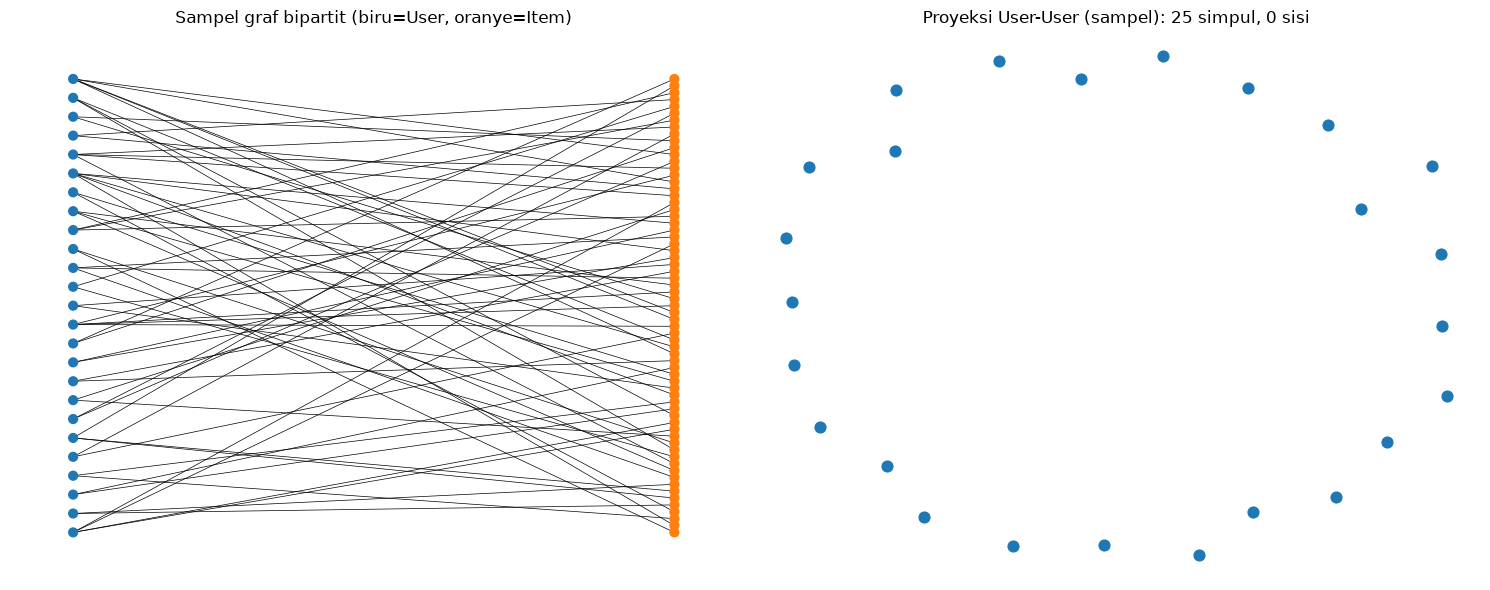

In [10]:
# Plot networkx: sampel bipartit + proyeksi User-User (reproducible)
rng = np.random.default_rng(SEED)
deg_u = np.asarray(X_bin.sum(axis=1)).ravel()
cand = np.where((deg_u >= 2) & (deg_u <= 6))[0]
samp = rng.choice(cand, size=min(25, len(cand)), replace=False)

B = nx.Graph()
for r in samp:
    for c in X_bin[r].indices:
        B.add_edge(f"U{users[r]}", f"I{items[c]}")
U_nodes = [n for n in B if n.startswith("U")]

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pos = nx.bipartite_layout(B, U_nodes)
nx.draw(B, pos, ax=ax[0], node_size=40, width=0.5,
        node_color=["tab:blue" if n.startswith("U") else "tab:orange" for n in B])
ax[0].set_title("Sampel graf bipartit (biru=User, oranye=Item)")
P_user = nx.bipartite.weighted_projected_graph(B, U_nodes)
nx.draw(P_user, nx.spring_layout(P_user, seed=SEED), ax=ax[1], node_size=60, width=0.8, node_color="tab:blue")
ax[1].set_title(f"Proyeksi User-User (sampel): {P_user.number_of_nodes()} simpul, {P_user.number_of_edges()} sisi")
plt.tight_layout(); plt.show()

**Karakteristik VSM User:** matriks `Visitor × Item` berbentuk (865.515, 189.762), artinya setiap User adalah vektor berdimensi 189.762 (jumlah Item unik). Matriks ini sangat *sparse*: hanya 1.302.017 elemen tak-nol (density 7,93×10⁻⁶, sparsity 99,9992%). Median interaksi per User hanya 1 item (rata-rata 1,50; maksimum 3.203), dan hanya 169.711 User (±19,6%) yang punya ≥ 2 item. Artinya sebagian besar vektor User hanya memiliki satu elemen tak-nol.

Plot networkx memakai sampel 25 User (2-6 item) yang dipilih acak dengan seed tetap. Graf bipartit (kiri) menunjukkan tiap User hanya menyentuh sebagian kecil Item, sedangkan proyeksi User-User pada sampel ini tidak memiliki sisi sama sekali (25 simpul, 0 sisi). Hal ini wajar karena dari 865.515 User hanya 25 yang diambil, sehingga peluang dua di antaranya berbagi Item sangat kecil. Ini bukan berarti seluruh graf tidak terhubung; di graf penuh hanya 5,37% User yang tidak berbagi Item dengan User lain.

### (Soal 5) VSM terhadap simpul Item
Setiap Item direpresentasikan sebagai vektor pada ruang User (dimensi = jumlah Visitor), yaitu transpos dari matriks sebelumnya.

[VSM Item] shape=(189762, 865515) | dimensi vektor=865,515 (User) | nnz=1,302,017 | density=7.93e-06 | sparsity=99.9992%
   interaksi/vektor: min=1, median=2, mean=6.86, max=1843


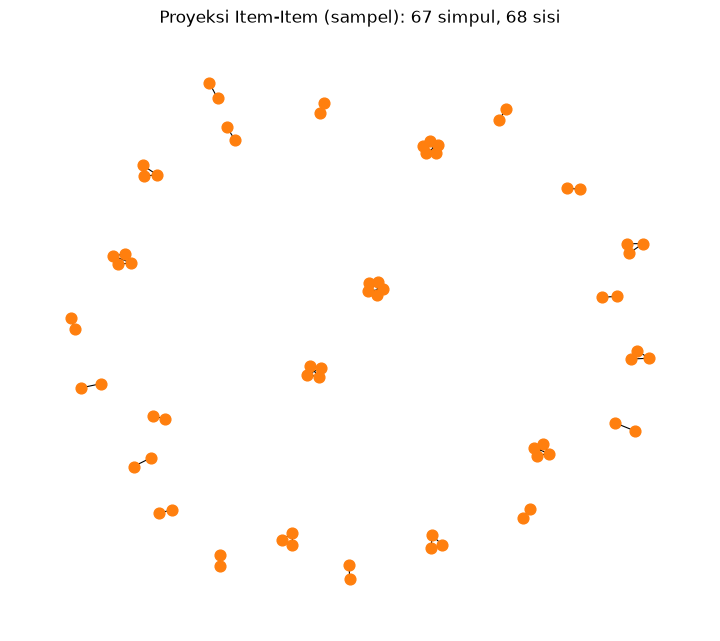

In [11]:
XT_bin = X_bin.T.tocsr()
describe(XT_bin, "VSM Item", "User")

I_nodes = [n for n in B if n.startswith("I")]
P_item = nx.bipartite.weighted_projected_graph(B, I_nodes)
plt.figure(figsize=(7, 6))
nx.draw(P_item, nx.spring_layout(P_item, seed=SEED), node_size=60, width=0.8, node_color="tab:orange")
plt.title(f"Proyeksi Item-Item (sampel): {P_item.number_of_nodes()} simpul, {P_item.number_of_edges()} sisi")
plt.show()

**Karakteristik VSM Item:** matriks berbentuk (189.762, 865.515), yaitu transpos dari VSM User sehingga jumlah elemen tak-nol dan density-nya sama (1.302.017 dan 7,93×10⁻⁶). Perbedaannya ada pada sebaran: setiap Item adalah vektor berdimensi 865.515 (jumlah User), dengan median 2 User per Item (rata-rata 6,86; maksimum 1.843). Vektor Item sedikit lebih "padat" dibanding vektor User (median 2 vs 1), tetapi sebagian Item (38,59%) hanya disentuh 1 User.

Proyeksi Item-Item pada sampel menghasilkan 67 simpul dan 68 sisi. Graf terpecah menjadi gugus-gugus kecil yang saling lepas. Tiap gugus berasal dari satu User sampel: Item-Item yang pernah diinteraksi User yang sama saling terhubung, sehingga User dengan n item membentuk gugus berisi n Item yang saling terhubung. Antar gugus tidak ada Item bersama, sesuai sifat data yang sparse.

### (Soal 6) Perbandingan proyeksi (efektif / efisien)
Ukuran proyeksi dapat diestimasi tanpa menghitung penuh: jumlah pasangan simpul yang berbagi tetangga.
- Proyeksi User-User: Σ over Item C(deg(item), 2)
- Proyeksi Item-Item: Σ over User C(deg(user), 2)

In [21]:
deg_user = np.asarray(X_bin.sum(axis=1)).ravel()
deg_item = np.asarray(X_bin.sum(axis=0)).ravel()
c2 = lambda d: float((d*(d-1)/2).sum())

# terisolasi sungguhan = tidak punya satu pun tetangga di graf proyeksi
iso_user = 100 * ((X_bin   @ (deg_item > 1).astype(float)) == 0).mean()
iso_item = 100 * ((X_bin.T @ (deg_user > 1).astype(float)) == 0).mean()

summary = pd.DataFrame({
    "proyeksi": ["User-User", "Item-Item"],
    "jumlah_simpul": [len(users), len(items)],
    "dimensi_VSM": [len(items), len(users)],
    "maks_sisi_kandidat": [c2(deg_item), c2(deg_user)],
    "rasio_sisi_per_simpul": [c2(deg_item)/len(users), c2(deg_user)/len(items)],
    "simpul_1_interaksi_%": [100*(deg_user<2).mean(), 100*(deg_item<2).mean()],
    "simpul_terisolasi_%": [iso_user, iso_item],
})
pd.options.display.float_format = "{:,.2f}".format
display(summary)

,proyeksi,jumlah_simpul,dimensi_VSM,maks_sisi_kandidat,rasio_sisi_per_simpul,simpul_1_interaksi_%,simpul_terisolasi_%
0,User-User,865515,189762,"36,768,550.00",42.48,80.39,5.37
1,Item-Item,189762,865515,"19,288,256.00",101.64,38.59,37.72


**Kesimpulan perbandingan proyeksi** (angka dari tabel di atas):

| Aspek | User-User | Item-Item | Lebih baik |
|---|---|---|---|
| Jumlah simpul | 865.515 | 189.762 | Item-Item (±4,6× lebih kecil) |
| Sisi kandidat maksimum | 36,8 juta | 19,3 juta | Item-Item (±1,9× lebih sedikit) |
| Simpul terisolasi | 5,37% | 37,72% | User-User |

- **Efisiensi:** Item-Item lebih efisien. Simpulnya 4,6× lebih sedikit dan sisi kandidatnya 1,9× lebih sedikit, sehingga matriks similarity-nya jauh lebih kecil.
- **Efektivitas (cakupan):** User-User lebih efektif karena 94,6% User punya minimal satu tetangga, sedangkan pada Item-Item 37,72% Item tidak punya tetangga sama sekali (Item yang hanya disentuh User yang cuma berinteraksi dengan Item itu). Meski 80,39% User hanya memiliki 1 item, hampir semuanya masih berbagi Item populer dengan User lain.
- **Keputusan:** similarity pada Soal 7 dan KNN pada 2.2 memakai proyeksi **User-User**, karena tujuannya merekomendasikan Item kepada seorang User dari tetangganya (user-based KNN), dan proyeksi ini memberi cakupan terbaik. Biaya komputasinya ditekan dengan menghitung similarity hanya untuk **satu User acuan** terhadap semua User (satu baris matriks), tidak membangun seluruh matriks 865.515 × 865.515.

### (Soal 7) Perhitungan similarity pada graf terproyeksi
Metrik: cosine similarity pada vektor biner User (tetangga di ruang Item). Pilih *reference user* secara acak dan reproducible (seed tetap) dari User yang ada di train dan test, dengan >= 3 item di train.

In [13]:
def cosine_user_sims(uid_pos, X=X_bin):
    """Cosine similarity satu User terhadap semua User (sparse, cepat)."""
    x = X[uid_pos]
    dots = (X @ x.T).toarray().ravel()
    norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())
    sims = dots / (norms * norms[uid_pos] + 1e-12)
    sims[uid_pos] = -1                      # buang diri sendiri
    return sims

def top_k_neighbors(uid_pos, k=5):
    sims = cosine_user_sims(uid_pos)
    order = np.lexsort((users, -sims))      # urut sim desc, tie-break visitorId asc (deterministik)
    top = order[:k]
    return [(int(users[j]), float(sims[j])) for j in top]

# --- pemilihan user acak (reproducible) ---
test_users = set(test["visitorid"].unique())
cand_users = [u for u in users[deg_user >= 3] if u in test_users]
rs = np.random.default_rng(SEED)
REF_USER = int(rs.choice(np.sort(cand_users)))
print("Jumlah kandidat:", len(cand_users), "| REF_USER =", REF_USER)

neigh = top_k_neighbors(uidx[REF_USER], k=5)
print("Top-5 tetangga (Python):"); display(pd.DataFrame(neigh, columns=["visitorId", "cosine"]))

Jumlah kandidat: 4113 | REF_USER = 127156
Top-5 tetangga (Python):


,visitorId,cosine
0,333196,0.50
1,533194,0.50
2,687559,0.50
3,763365,0.50
4,76226,0.35


**(a) CYPHER untuk 5 record dengan similarity tertinggi** (cosine biner = |irisan item| / sqrt(|item A| x |item B|):

In [14]:
Q_TOP5 = """
MATCH (a:Visitor {visitorId: $uid})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
      <-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b:Visitor)
WHERE a <> b
WITH a, b, count(DISTINCT i) AS inter
MATCH (a)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(ia:Item)
WITH a, b, inter, count(DISTINCT ia) AS na
MATCH (b)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(ib:Item)
WITH a, b, inter, na, count(DISTINCT ib) AS nb
RETURN b.visitorId AS neighbor, inter, na, nb,
       inter / sqrt(toFloat(na) * toFloat(nb)) AS cosine
ORDER BY cosine DESC, neighbor ASC
LIMIT 5
"""
df_top5 = run_df(Q_TOP5, uid=REF_USER)
display(df_top5)

,neighbor,inter,na,nb,cosine
0,333196,1,4,1,0.50
1,533194,1,4,1,0.50
2,687559,1,4,1,0.50
3,763365,1,4,1,0.50
4,76226,1,4,2,0.35


Hasil query di Neo4j Browser:

![Top-5 similarity](docs/top5_query.png)

**(b) Tulis kembali nilai similarity ke graf** sebagai relasi `SIMILAR_TO {score}`:

In [15]:
Q_WRITE_SIM = """
UNWIND $rows AS row
MATCH (a:Visitor {visitorId: $uid}), (b:Visitor {visitorId: row.neighbor})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.cosine, s.metric = 'cosine'
"""
with driver.session(database=DB) as session:
    session.run("MATCH ()-[s:SIMILAR_TO]->() DELETE s")  # idempoten
    session.run(Q_WRITE_SIM, uid=REF_USER, rows=df_top5[["neighbor", "cosine"]].to_dict("records"))

Q_CHECK = """
MATCH (a:Visitor {visitorId: $uid})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS user, b.visitorId AS neighbor, s.score AS score
ORDER BY score DESC
"""
display(run_df(Q_CHECK, uid=REF_USER))

,user,neighbor,score
0,127156,533194,0.50
1,127156,333196,0.50
2,127156,763365,0.50
3,127156,687559,0.50
4,127156,76226,0.35


Hasil query di Neo4j Browser:

![Similarity pada graf](docs/similar_to.png)

### (Soal 8) Kondisi graf **sebelum** dan **sesudah** perhitungan similarity
Query yang dijalankan di Neo4j Browser (hasil graf divisualisasikan di Browser; di bawah ditampilkan ulang dengan networkx).
```cypher
// SEBELUM: User + item yang diinteraksi (belum ada SIMILAR_TO)
MATCH p = (a:Visitor {visitorId: <REF_USER>})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(:Item)
RETURN p LIMIT 25;

// SESUDAH: relasi similarity terhadap 5 tetangga
MATCH p = (a:Visitor {visitorId: <REF_USER>})-[:SIMILAR_TO]->(:Visitor)
RETURN p;
```

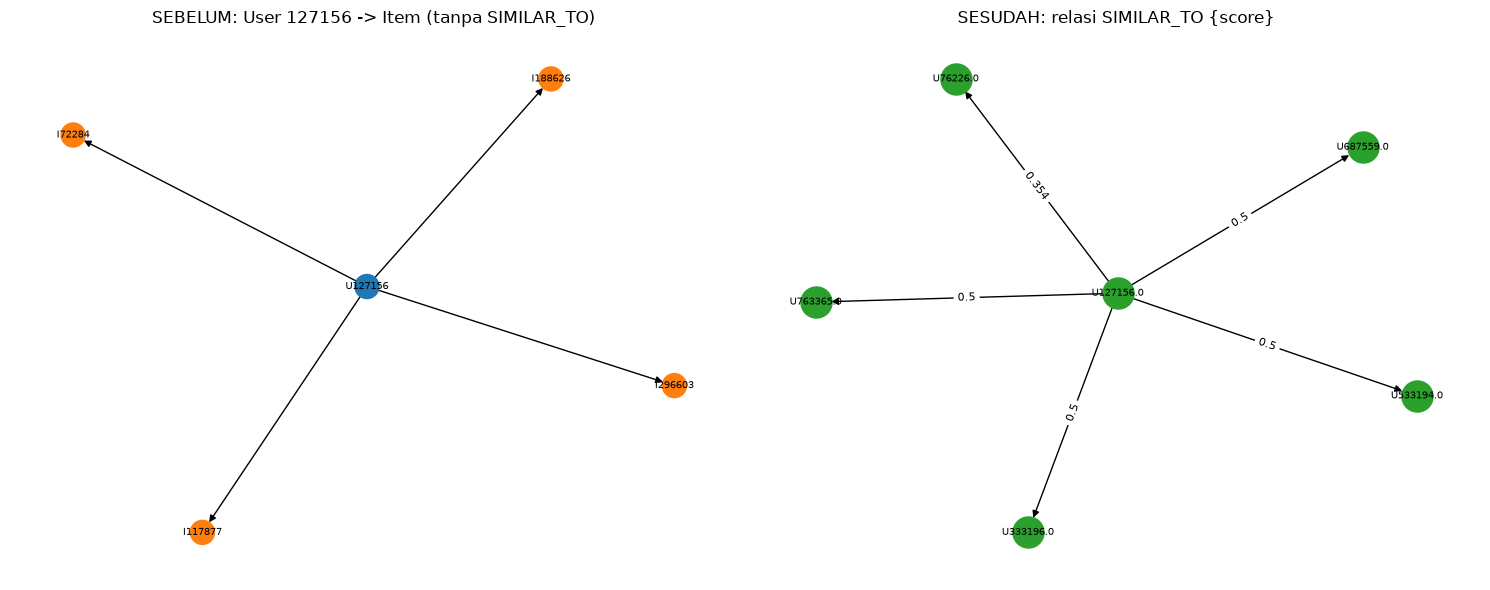

In [16]:
Q_BEFORE = """
MATCH (a:Visitor {visitorId: $uid})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN a.visitorId AS u, type(r) AS rel, i.itemId AS i LIMIT 25
"""
before = run_df(Q_BEFORE, uid=REF_USER)
after  = run_df(Q_CHECK, uid=REF_USER)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
G1 = nx.DiGraph()
for _, r in before.iterrows():
    G1.add_edge(f"U{r.u}", f"I{r.i}", rel=r.rel)
nx.draw(G1, nx.spring_layout(G1, seed=SEED), ax=ax[0], with_labels=True, font_size=7, node_size=300,
        node_color=["tab:blue" if n.startswith("U") else "tab:orange" for n in G1])
ax[0].set_title(f"SEBELUM: User {REF_USER} -> Item (tanpa SIMILAR_TO)")

G2 = nx.DiGraph()
for _, r in after.iterrows():
    G2.add_edge(f"U{r.user}", f"U{r.neighbor}", w=round(r.score, 3))
pos2 = nx.spring_layout(G2, seed=SEED)
nx.draw(G2, pos2, ax=ax[1], with_labels=True, font_size=7, node_size=500, node_color="tab:green")
nx.draw_networkx_edge_labels(G2, pos2, edge_labels=nx.get_edge_attributes(G2, "w"), ax=ax[1], font_size=8)
ax[1].set_title("SESUDAH: relasi SIMILAR_TO {score}")
plt.tight_layout(); plt.show()

Hasil di Neo4j Browser:

**Sebelum** perhitungan similarity:  
![Sebelum](docs/graf_sebelum.png)

**Sesudah** perhitungan similarity (relasi `SIMILAR_TO`):  
![Sesudah](docs/graf_sesudah.png)

**Pembacaan hasil:** pada kondisi *sebelum*, User 127156 hanya terhubung ke 4 Item yang ia interaksi (72284, 117877, 188626, 296603), dan tidak ada relasi antar User. Pada kondisi *sesudah*, muncul 5 relasi `SIMILAR_TO` dari User 127156 ke tetangga top-5: 4 tetangga bernilai 0,5 (333196, 533194, 687559, 763365) dan 1 tetangga bernilai 0,354 (76226). Nilai 0,5 muncul karena tetangga tersebut hanya punya 1 item (yang sama dengan item User 127156), sehingga cosine = 1/√(4×1) = 0,5. Sedangkan 76226 punya 2 item dengan 1 irisan, sehingga 1/√(4×2) ≈ 0,354. Graf item-nya tidak berubah, hanya bertambah relasi antar User.

## 2.2 Analytics
### (Soal 1a) KNN User-based (k = 5): skrip rekomendasi
Proses acak: `np.random.default_rng(42)` terhadap User yang ada di train & test dengan >= 3 item train (sama dengan `REF_USER`, sehingga reproducible).  
Skor item kandidat = Σ cosine(User target, tetangga) untuk tiap tetangga yang berinteraksi dengan item tsb. Item yang sudah pernah diinteraksi User target (di train) dibuang.

In [17]:
K = 5
item_pop = np.asarray(X_bin.sum(axis=0)).ravel()
pop_order = np.lexsort((items, -item_pop))

def top_k_neighbors_new(pos, k=5):
    """Top-k tetangga (cosine) yang punya >=1 item baru bagi User target."""
    sims = cosine_user_sims(pos)
    order = np.lexsort((users, -sims))
    seen = set(X_bin[pos].indices)
    out = []
    for j in order:
        if sims[j] <= 0:
            break
        if not (set(X_bin[j].indices) - seen):
            continue
        out.append((int(users[j]), float(sims[j])))
        if len(out) == k:
            break
    return out

def recommend_knn(user_id, k=K, n_rec=5):
    pos = uidx[user_id]
    neigh = top_k_neighbors_new(pos, k)
    seen = set(X_bin[pos].indices)
    scores = {}
    for nid, sim in neigh:
        for c in X_bin[uidx[nid]].indices:
            if c in seen:
                continue
            scores[c] = scores.get(c, 0.0) + sim
    ranked = sorted(scores.items(), key=lambda t: (-t[1], items[t[0]]))[:n_rec]
    recs = [(int(items[c]), round(s, 4), "KNN") for c, s in ranked]

    if len(recs) < n_rec:   # fallback popularitas
        taken = seen | {c for c, _ in ranked}
        for c in pop_order:
            if c in taken:
                continue
            recs.append((int(items[c]), 0.0, "popularitas"))
            taken.add(c)
            if len(recs) == n_rec:
                break
    return neigh, recs

neigh, rec5 = recommend_knn(REF_USER, k=K, n_rec=5)
print("User acak:", REF_USER)
print("Tetangga KNN (k=5):"); display(pd.DataFrame(neigh, columns=["visitorId", "cosine"]))
print("Top-5 ranking rekomendasi:")
display(pd.DataFrame(rec5, columns=["itemId", "skor", "sumber"]))

User acak: 127156
Tetangga KNN (k=5):


,visitorId,cosine
0,76226,0.35
1,1034350,0.29
2,904871,0.25
3,163711,0.18
4,395736,0.12


Top-5 ranking rekomendasi:


,itemId,skor,sumber
0,186900,0.35,KNN
1,396362,0.29,KNN
2,450930,0.29,KNN
3,12950,0.25,KNN
4,328971,0.25,KNN


### (Soal 1b) 3 item yang diiklankan (k = 5)

In [18]:
# Mengambil tiga rekomendasi teratas
ads = rec5[:3]

print("Tiga item yang diiklankan (k=5):")

display(
    pd.DataFrame(
        ads,
        columns=["itemId", "skor", "sumber"]
    ).assign(
        rank=range(1, len(ads) + 1)
    ).set_index("rank")
)

Tiga item yang diiklankan (k=5):


,itemId,skor,sumber
rank,,,
1,186900,0.35,KNN
2,396362,0.29,KNN
3,450930,0.29,KNN


### (Soal 2) Evaluasi: Hit@5 dan NDCG@5
*Ground truth* = item yang diinteraksi User tsb pada **fold testing (P2)**. Evaluasi memakai daftar ranking top-5 (3 item iklan = 3 teratas dari daftar ini).

- **Hit@5** = 1 jika minimal satu item top-5 ada di ground truth, selain itu 0.  
- **NDCG@5** = DCG@5 / IDCG@5, dengan DCG = Σ rel_i / log2(i+1), i = 1..5 (rel biner).

In [19]:
def hit_at_k(rec, relevant, k=5):
    return int(any(i in relevant for i in rec[:k]))

def ndcg_at_k(rec, relevant, k=5):
    dcg = sum(1.0 / math.log2(r + 2) for r, i in enumerate(rec[:k]) if i in relevant)
    ideal = sum(1.0 / math.log2(r + 2) for r in range(min(len(relevant), k)))
    return dcg / ideal if ideal > 0 else 0.0

# (A) User acak: evaluasi 3 item iklan (hasil no. 1b)
ads_items = [i for i, _, _ in rec5[:3]]
gt_all   = set(test.loc[test["visitorid"] == REF_USER, "itemid"])
gt_train = set(train.loc[train["visitorid"] == REF_USER, "itemid"])
print("User acak                :", REF_USER)
print("3 item iklan             :", ads_items)
print("Ground truth (item di P2):", sorted(gt_all), "| sudah ada di P1:", sorted(gt_all & gt_train))
print(f"(a) Hit@5  = {hit_at_k(ads_items, gt_all)}")
print(f"(b) NDCG@5 = {ndcg_at_k(ads_items, gt_all):.4f}")

# (B) Pendukung: rata-rata 200 User acak (seed tetap), ground truth = item BARU di P2 
tg  = test.groupby("visitorid")["itemid"].apply(set)
trg = train.groupby("visitorid")["itemid"].apply(set)
pool = [u for u in cand_users if len(tg[u] - trg[u]) > 0]
samp = np.random.default_rng(SEED).choice(np.sort(pool), size=200, replace=False)

H, N = [], []
for u in samp:
    _, rc = recommend_knn(int(u))
    ri = [i for i, _, _ in rc][:3]          # 3 item iklan
    rel = tg[u] - trg[u]
    H.append(hit_at_k(ri, rel)); N.append(ndcg_at_k(ri, rel))
print(f"\nRata-rata 200 User (3 item iklan): Hit@5 = {np.mean(H):.4f} | NDCG@5 = {np.mean(N):.4f}")

User acak                : 127156
3 item iklan             : [186900, 396362, 450930]
Ground truth (item di P2): [296603] | sudah ada di P1: [296603]
(a) Hit@5  = 0
(b) NDCG@5 = 0.0000

Rata-rata 200 User (3 item iklan): Hit@5 = 0.0200 | NDCG@5 = 0.0093


In [22]:
H0, N0 = [], []
for u in samp:
    seen = set(X_bin[uidx[int(u)]].indices)
    rec = []
    for c in pop_order:
        if c in seen: continue
        rec.append(int(items[c]))
        if len(rec) == 3: break
    rel = tg[u] - trg[u]
    H0.append(hit_at_k(rec, rel)); N0.append(ndcg_at_k(rec, rel))
print(f"Baseline populer (3 item): Hit@5 = {np.mean(H0):.4f} | NDCG@5 = {np.mean(N0):.4f}")

Baseline populer (3 item): Hit@5 = 0.0050 | NDCG@5 = 0.0032


**Interpretasi hasil:**

- **User acak (127156):** 3 item iklan (186900, 396362, 450930) seluruhnya berasal dari KNN. Ground truth di P2 hanya berisi item 296603, yang sudah pernah diinteraksi User ini di P1. Karena item yang sudah pernah dilihat dikeluarkan dari rekomendasi, item tersebut tidak mungkin muncul, sehingga **Hit@5 = 0 dan NDCG@5 = 0**. Hasil nol ini disebabkan struktur ground truth-nya, bukan semata kegagalan model.
- **Rata-rata 200 User acak** (seed tetap, ground truth = item baru di P2): **Hit@5 = 0,02** (±4 dari 200 User mendapat minimal satu iklan yang tepat) dan **NDCG@5 = 0,0093**. Sebagai pembanding, rekomendasi populer top-3 hanya mencapai Hit@5 = 0,005 dan NDCG@5 = 0,0032, sehingga KNN sekitar 4× lebih baik, meski selisihnya berasal dari jumlah kejadian yang kecil.
- **Mengapa nilainya rendah:** data sangat sparse (median 1 interaksi per User), hanya 3 item yang ditampilkan, dan P2 berjarak sekitar 3 minggu dari P1 sehingga minat User dapat berubah. Dalam sistem rekomendasi implicit-feedback dengan data seperti ini, nilai Hit@5 di kisaran beberapa persen adalah hal yang wajar.

In [20]:
driver.close()